# Market Basket Analysis: Online Retail

Which products do customers buy together? This notebook mines **541,909 real transactions** from a UK online gift retailer to find product pairs that are bought together far more often than chance, using the **Apriori algorithm** and **association rules**.

The results answer three business questions:

1. Which products are most strongly linked?
2. Do buying patterns change with the time of day?
3. How much extra revenue could a simple "bundle" prompt generate?

**Dataset:** [Online Retail, UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/352/online+retail) (CC BY 4.0). Download `Online Retail.xlsx` and place it in the same folder as this notebook.

## 1. Load the data

Each row is one product line on one invoice: invoice number, product, quantity, date, unit price, customer ID and country.

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd

df = pd.read_excel('Online Retail.xlsx')
print(df.shape)
df.head()

(541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## 2. Explore the data

Check column types, missing values and value ranges. Two things stand out: `CustomerID` has many missing values, and `Quantity` and `UnitPrice` include negative values, which point to cancellations and adjustments.

In [ ]:
df.info()
df.isnull().sum()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


## 3. Clean the data

Remove rows that do not represent a real sale:

- **Cancelled orders**: invoice numbers starting with `C`
- **Returns and adjustments**: quantity of zero or below
- **Free or invalid items**: unit price of zero or below
- **Rows with no product description**

This keeps **530,104** of 541,909 rows.

In [ ]:
df_clean = df[~df['InvoiceNo'].astype(str).str.startswith('C')]
df_clean = df_clean[df_clean['Quantity'] > 0]
df_clean = df_clean[df_clean['UnitPrice'] > 0]
df_clean = df_clean.dropna(subset=['Description'])
print(df_clean.shape)

(530104, 8)


## 4. Focus on the UK market

The UK makes up over 90% of transactions. Analysing one market avoids mixing different customer behaviours and keeps the basket matrix manageable.

In [ ]:
df_uk = df_clean[df_clean['Country'] == 'United Kingdom']
print(df_uk.shape)

(485123, 8)


## 5. Keep frequently bought products

Products that appear on fewer than 300 invoices cannot produce reliable patterns, so they are filtered out. This leaves **404 products** across about 218,000 rows.

In [ ]:
product_counts = df_uk.groupby('Description')['InvoiceNo'].nunique()
popular_products = product_counts[product_counts >= 300].index

df_uk_filtered = df_uk[df_uk['Description'].isin(popular_products)].copy()

print(df_uk_filtered.shape)
print(df_uk_filtered['Description'].nunique())

(217748, 8)
404


## 6. Build the basket matrix

Reshape the data so each **row is one invoice** and each **column is one product**, holding the total quantity bought. This gives a matrix of **16,517 baskets × 404 products**.

In [ ]:
basket = (df_uk_filtered.groupby(['InvoiceNo', 'Description'])['Quantity']
          .sum().unstack().reset_index().fillna(0)
          .set_index('InvoiceNo'))

basket.shape

(16517, 404)

Apriori only needs to know *whether* a product was in a basket, not how many, so the matrix is converted to True/False.

In [ ]:
basket_encoded = (basket > 0)
basket_encoded.shape

(16517, 404)

## 7. Find frequent itemsets with Apriori

An **itemset** is a group of products bought together. **Support** is the share of all baskets that contain it. Apriori finds every itemset with support of at least **3%**, meaning it appears in roughly 500 or more baskets.

The single most common product is the *White Hanging Heart T-Light Holder*, in 13% of all baskets.

In [ ]:
from mlxtend.frequent_patterns import apriori, association_rules

frequent_itemsets = apriori(basket_encoded, min_support=0.03, use_colnames=True, low_memory=True)
frequent_itemsets.sort_values('support', ascending=False).head(10)

,support,itemsets
144,0.130895,(WHITE HANGING HEART T-LIGHT HOLDER)
63,0.117152,(JUMBO BAG RED RETROSPOT)
114,0.102016,(REGENCY CAKESTAND 3 TIER)
100,0.096446,(PARTY BUNTING)
83,0.084277,(LUNCH BAG RED RETROSPOT)
9,0.083005,(ASSORTED COLOUR BIRD ORNAMENT)
122,0.075135,(SET OF 3 CAKE TINS PANTRY DESIGN )
90,0.073803,(NATURAL SLATE HEART CHALKBOARD )
77,0.073621,(LUNCH BAG BLACK SKULL.)
45,0.070473,(HEART OF WICKER SMALL)


## 8. Generate association rules

A rule reads **"customers who buy A also buy B"**, measured three ways:

| Metric | Meaning |
|---|---|
| **Support** | How often A and B appear together across all baskets |
| **Confidence** | Of the baskets containing A, the share that also contain B |
| **Lift** | How much more likely B is when A is in the basket, compared with chance. **Lift > 1** means a real association. |

**Top finding:** 82% of customers who buy the *Pink Regency Teacup and Saucer* also buy the *Green* one, a lift of **14.5×**. The strongest rules are matching sets (teacups in different colours, gardening kneeling pads, alarm clocks), which suggests customers collect a range.

In [ ]:
rules = association_rules(frequent_itemsets, metric='lift', min_threshold=1.0)
rules = rules.sort_values('lift', ascending=False)
rules[['antecedents','consequents','support','confidence','lift']].head(10)

,antecedents,consequents,support,confidence,lift
5,(PINK REGENCY TEACUP AND SAUCER),(GREEN REGENCY TEACUP AND SAUCER),0.034873,0.820513,14.541213
4,(GREEN REGENCY TEACUP AND SAUCER),(PINK REGENCY TEACUP AND SAUCER),0.034873,0.618026,14.541213
45,(ROSES REGENCY TEACUP AND SAUCER ),(PINK REGENCY TEACUP AND SAUCER),0.032996,0.570084,13.413208
44,(PINK REGENCY TEACUP AND SAUCER),(ROSES REGENCY TEACUP AND SAUCER ),0.032996,0.776353,13.413208
3,(GARDENERS KNEELING PAD CUP OF TEA ),(GARDENERS KNEELING PAD KEEP CALM ),0.032754,0.721333,13.267553
2,(GARDENERS KNEELING PAD KEEP CALM ),(GARDENERS KNEELING PAD CUP OF TEA ),0.032754,0.602450,13.267553
6,(GREEN REGENCY TEACUP AND SAUCER),(ROSES REGENCY TEACUP AND SAUCER ),0.042381,0.751073,12.976435
7,(ROSES REGENCY TEACUP AND SAUCER ),(GREEN REGENCY TEACUP AND SAUCER),0.042381,0.732218,12.976435
0,(ALARM CLOCK BAKELIKE GREEN),(ALARM CLOCK BAKELIKE RED ),0.034086,0.642694,11.414385
1,(ALARM CLOCK BAKELIKE RED ),(ALARM CLOCK BAKELIKE GREEN),0.034086,0.605376,11.414385


## 9. Do patterns change with the time of day?

Each transaction is labelled Morning (5–12), Afternoon (12–17), Evening (17–21) or Night. Most orders happen in the afternoon, and there are no night orders in the filtered data.

In [ ]:
def get_time_period(hour):
    if 5 <= hour < 12:
        return 'Morning'
    elif 12 <= hour < 17:
        return 'Afternoon'
    elif 17 <= hour < 21:
        return 'Evening'
    else:
        return 'Night'

df_uk_filtered['Hour'] = df_uk_filtered['InvoiceDate'].dt.hour
df_uk_filtered['TimePeriod'] = df_uk_filtered['Hour'].apply(get_time_period)

df_uk_filtered['TimePeriod'].value_counts()

,count
TimePeriod,
Afternoon,141146
Morning,61835
Evening,14767


Apriori is then run separately for each time period. The top pairs are **the same in the morning and the afternoon** (the Regency teacup set), with nearly identical lift. In the evening, with far fewer orders, the strongest rules shift to larger combinations of teacups and matching tea plates.

**Takeaway:** product pairings are stable across the day, so a recommendation or bundle strategy does not need to be time-specific.

In [ ]:
from mlxtend.frequent_patterns import apriori, association_rules

def get_rules_for_period(period_name):
    period_data = df_uk_filtered[df_uk_filtered['TimePeriod'] == period_name]

    basket_p = (period_data.groupby(['InvoiceNo', 'Description'])['Quantity']
                .sum().unstack().reset_index().fillna(0)
                .set_index('InvoiceNo'))
    basket_p_encoded = (basket_p > 0)

    freq_items = apriori(basket_p_encoded, min_support=0.03, use_colnames=True, low_memory=True)

    if len(freq_items) == 0:
        print(f"{period_name}: no frequent itemsets found at this support level")
        return None

    rules_p = association_rules(freq_items, metric='lift', min_threshold=1.0)
    rules_p = rules_p.sort_values('lift', ascending=False)
    return rules_p

morning_rules = get_rules_for_period('Morning')
afternoon_rules = get_rules_for_period('Afternoon')
evening_rules = get_rules_for_period('Evening')

print("=== MORNING TOP PAIRS ===")
print(morning_rules[['antecedents','consequents','lift']].head(5) if morning_rules is not None else "none")

print("\n=== AFTERNOON TOP PAIRS ===")
print(afternoon_rules[['antecedents','consequents','lift']].head(5) if afternoon_rules is not None else "none")

print("\n=== EVENING TOP PAIRS ===")
print(evening_rules[['antecedents','consequents','lift']].head(5) if evening_rules is not None else "none")

=== MORNING TOP PAIRS ===
                           antecedents                         consequents  \
3     (PINK REGENCY TEACUP AND SAUCER)   (GREEN REGENCY TEACUP AND SAUCER)   
2    (GREEN REGENCY TEACUP AND SAUCER)    (PINK REGENCY TEACUP AND SAUCER)   
26    (PINK REGENCY TEACUP AND SAUCER)  (ROSES REGENCY TEACUP AND SAUCER )   
27  (ROSES REGENCY TEACUP AND SAUCER )    (PINK REGENCY TEACUP AND SAUCER)   
5   (ROSES REGENCY TEACUP AND SAUCER )   (GREEN REGENCY TEACUP AND SAUCER)   

         lift  
3   15.032928  
2   15.032928  
26  13.765939  
27  13.765939  
5   13.067838  

=== AFTERNOON TOP PAIRS ===
                           antecedents                         consequents  \
7     (PINK REGENCY TEACUP AND SAUCER)   (GREEN REGENCY TEACUP AND SAUCER)   
6    (GREEN REGENCY TEACUP AND SAUCER)    (PINK REGENCY TEACUP AND SAUCER)   
56    (PINK REGENCY TEACUP AND SAUCER)  (ROSES REGENCY TEACUP AND SAUCER )   
57  (ROSES REGENCY TEACUP AND SAUCER )    (PINK REGENCY TEACUP AND S

## 10. Estimate the value of a bundle offer

Taking the strongest rule (Pink → Green Regency teacup): **126 invoices** included the pink teacup but **not** the green one. If a "frequently bought together" prompt converted even 30% of these, the extra revenue would be about **£147** for this single pair, from the existing customer base alone. Applied across all strong rules, the same approach adds up.

In [ ]:
# Calculate average price for each item (using already-cleaned UK data)
item_prices = df_uk_filtered.groupby('Description')['UnitPrice'].mean()

# Take the top overall rule (Pink + Green Regency Teacup and Saucer)
item_a = 'PINK REGENCY TEACUP AND SAUCER'
item_b = 'GREEN REGENCY TEACUP AND SAUCER'

price_a = item_prices[item_a]
price_b = item_prices[item_b]

# How many invoices bought item_a but NOT item_b (missed bundle opportunity)
invoices_with_a = set(df_uk_filtered[df_uk_filtered['Description'] == item_a]['InvoiceNo'])
invoices_with_b = set(df_uk_filtered[df_uk_filtered['Description'] == item_b]['InvoiceNo'])

missed_bundle_invoices = invoices_with_a - invoices_with_b

print(f"{item_a}: avg price £{price_a:.2f}")
print(f"{item_b}: avg price £{price_b:.2f}")
print(f"Invoices with {item_a} but NOT {item_b}: {len(missed_bundle_invoices)}")
print(f"If even 30% of these added {item_b} via a bundle prompt:")
potential_revenue = len(missed_bundle_invoices) * 0.30 * price_b
print(f"Estimated additional revenue: £{potential_revenue:.2f}")

PINK REGENCY TEACUP AND SAUCER: avg price £3.76
GREEN REGENCY TEACUP AND SAUCER: avg price £3.90
Invoices with PINK REGENCY TEACUP AND SAUCER but NOT GREEN REGENCY TEACUP AND SAUCER: 126
If even 30% of these added GREEN REGENCY TEACUP AND SAUCER via a bundle prompt:
Estimated additional revenue: £147.41


Number of distinct products appearing on each side of the rules:

In [ ]:
print(rules['antecedents'].apply(lambda x: list(x)[0]).nunique())
print(rules['consequents'].apply(lambda x: list(x)[0]).nunique())

24
24


## 11. Visualise the results

### Product association network

Each node is a product and each line is a strong rule; thicker lines mean higher lift. The products form tight clusters, such as the Regency teacup family, rather than one connected web.

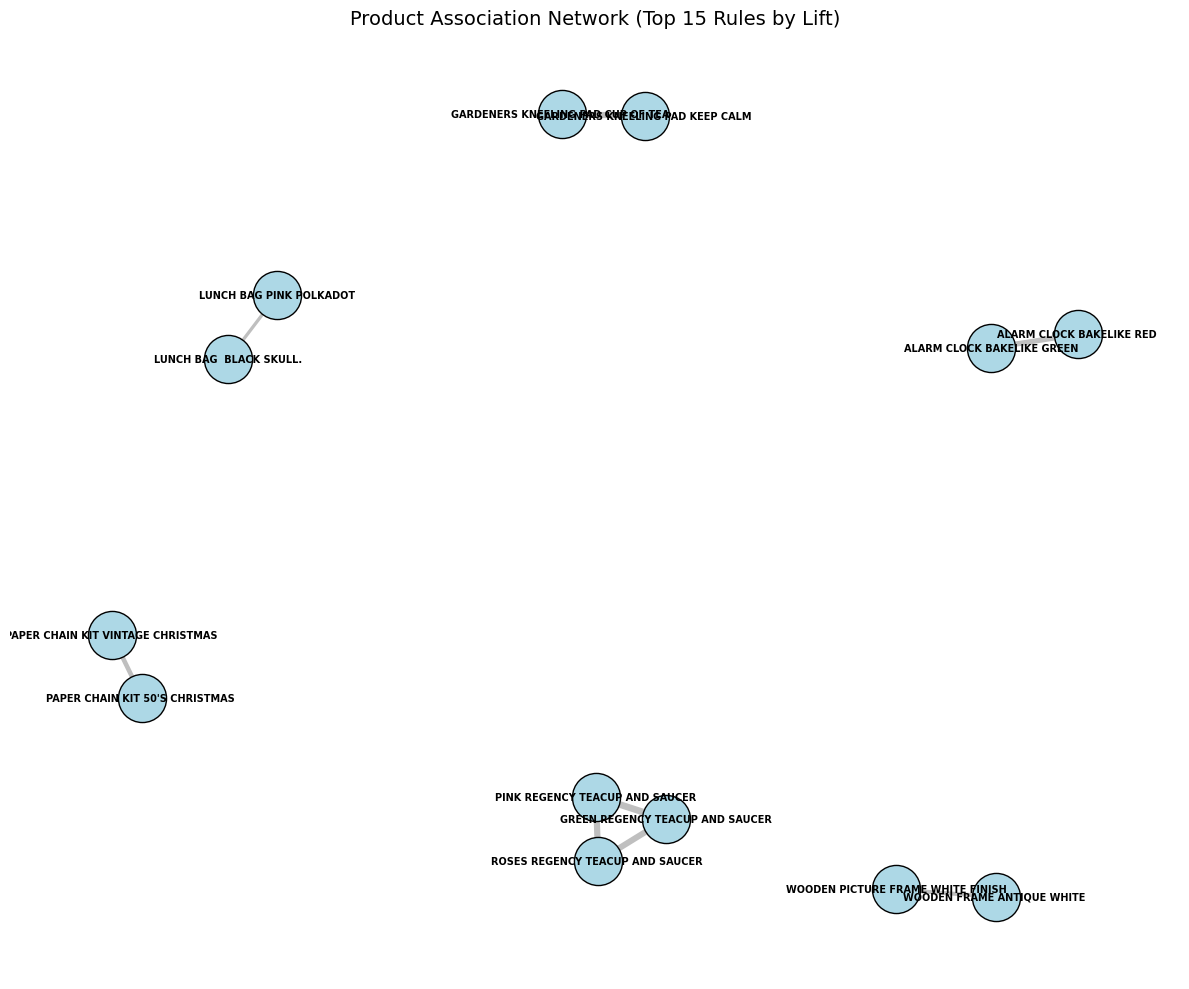

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt

# Take top 15 rules by lift for a clean, readable graph
top_rules = rules.sort_values('lift', ascending=False).head(15)

G = nx.Graph()
for _, row in top_rules.iterrows():
    item_a = list(row['antecedents'])[0]
    item_b = list(row['consequents'])[0]
    G.add_edge(item_a, item_b, weight=row['lift'])

plt.figure(figsize=(12, 10))
pos = nx.spring_layout(G, k=0.8, seed=42)

weights = [G[u][v]['weight'] for u, v in G.edges()]
nx.draw_networkx_edges(G, pos, width=[w/3 for w in weights], alpha=0.5, edge_color='gray')
nx.draw_networkx_nodes(G, pos, node_size=1200, node_color='lightblue', edgecolors='black')
nx.draw_networkx_labels(G, pos, font_size=7, font_weight='bold')

plt.title('Product Association Network (Top 15 Rules by Lift)', fontsize=14)
plt.axis('off')
plt.tight_layout()
plt.savefig('images/product_network.png', dpi=150, bbox_inches='tight')
plt.show()

### Top product pairings by lift

The 15 strongest rules, with duplicate pairs (A→B and B→A) merged. The dashed line at 1× marks "no association".

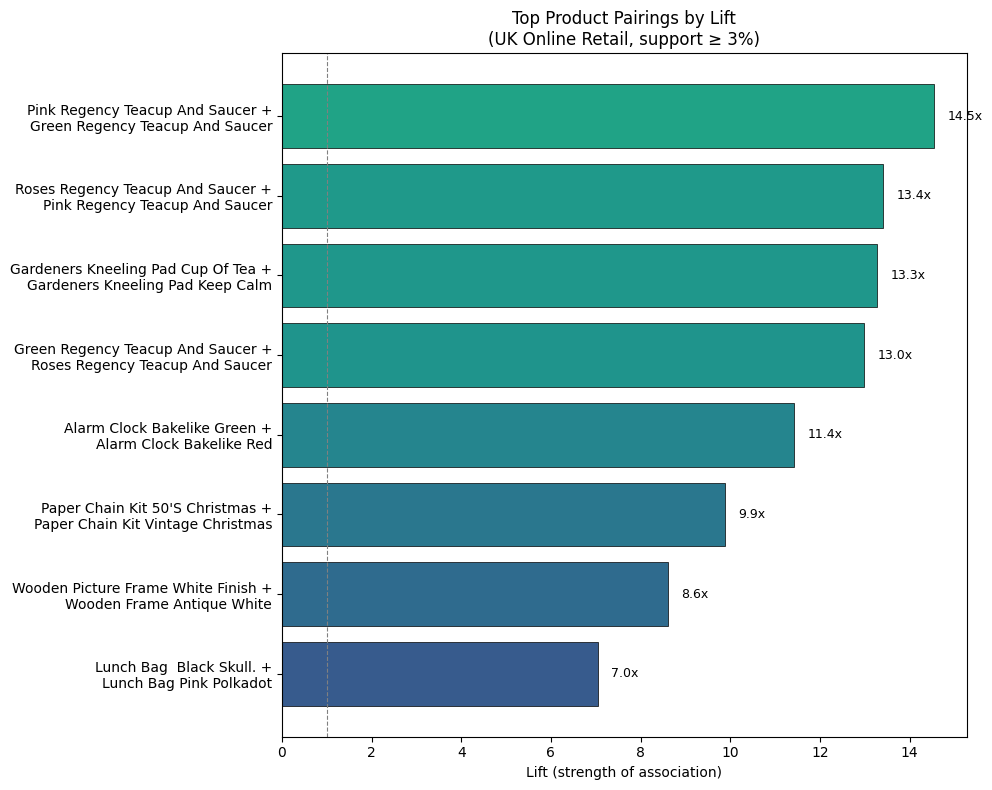

In [ ]:
import matplotlib.pyplot as plt

top_rules = rules.sort_values('lift', ascending=False).head(15)

seen = set()
pairs = []
for _, row in top_rules.iterrows():
    a = list(row['antecedents'])[0]
    b = list(row['consequents'])[0]
    key = frozenset([a, b])
    if key not in seen:
        seen.add(key)
        pairs.append((f"{a.strip().title()} +\n{b.strip().title()}", row['lift']))

pairs = sorted(pairs, key=lambda x: x[1])
labels = [p[0] for p in pairs]
lifts = [p[1] for p in pairs]

fig, ax = plt.subplots(figsize=(10, 8))
colors = plt.cm.viridis([min(l/25, 1) for l in lifts])
bars = ax.barh(labels, lifts, color=colors, edgecolor='black', linewidth=0.5)

for bar, lift in zip(bars, lifts):
    ax.text(lift + 0.3, bar.get_y() + bar.get_height()/2, f'{lift:.1f}x', va='center', fontsize=9)

ax.set_xlabel('Lift (strength of association)')
ax.set_title('Top Product Pairings by Lift\n(UK Online Retail, support ≥ 3%)')
ax.axvline(x=1, color='gray', linestyle='--', linewidth=0.8)
plt.tight_layout()
plt.savefig('images/top_pairs_bar.png', dpi=150, bbox_inches='tight')
plt.show()

## 12. Conclusions

- **Strong, clear patterns exist.** The top rules have lift above 11×, far beyond chance.
- **Customers collect sets.** The strongest pairings are colour or design variants of the same product, which points to "complete the set" bundles and cross-sell prompts.
- **Patterns are stable through the day**, so one recommendation strategy works for all hours.
- **Bundling has measurable value.** One pair alone shows about £147 in missed revenue at a modest 30% conversion.

**Limitations:** the data covers one year of one retailer, mostly wholesale customers in the UK. The 3% support threshold focuses on popular products and misses rarer but potentially valuable combinations. The revenue estimate assumes a 30% conversion rate rather than measuring one.